# N4 · Troca de produto na linha SMT · Aula 6 · Classificação

**Pergunta do projeto:** a troca passa de 42 minutos? Em outras palavras: quais trocas demoradas o modelo consegue apontar antes?

Este notebook é só da **classificação**:
1. **Retomar os dados** (células prontas): ler a base, separar treino, validação e teste e preparar as entradas.
2. **Classificação:** prever **sim ou não** com uma árvore e contar os **verdadeiros positivos, falsos negativos e falsos positivos**.

**Meta:** escolher a profundidade da árvore de classificação pela validação e salvar `N4_classificacao.json`. A teoria foi nas Aulas 5 e 6; este notebook é a prática da Aula 6. O **teste** da classificação é aberto **uma única vez**, no fim deste notebook (seção 2.8), depois de todas as escolhas. Os números do teste entram na apresentação de **09/11**.

**Como usar este notebook:**
1. Salve uma cópia no Drive (Arquivo → Salvar uma cópia no Drive).
2. Execute as células de cima para baixo.
3. Edite só as células **Sua vez** (complete os espaços em branco), a lista `PROFUNDIDADES` (primeira linha da célula da seção 2.5) e a **Resposta** da seção 2.6. Todas as outras são **células prontas: execute sem alterar**.

**Para continuar depois:** salve uma cópia no Drive (Arquivo → Salvar uma cópia no Drive) e baixe o `.json` do fim.

---
# 1 · Retomar os dados (células prontas)

> **Contexto:** A base é a mesma da regressão, mas aqui a divisão em treino, validação e teste **mantém a proporção de "sim" e "não" em cada parte** (`stratify`). Com `random_state=42`, o sorteio é sempre o mesmo: o teste continua guardado.

Envie `N4_limpo.csv` (o da Aula 3 ou o da pasta desta aula) e execute as células deste bloco.

In [1]:
# Célula pronta: execute sem alterar (lê o arquivo de dados)
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

ARQUIVO = 'N4_limpo.csv'
def achar(nome):
    for pasta in [Path('dataset/raw'), Path('.')]:
        if (pasta / nome).exists():
            return pasta / nome
    return None

if achar(ARQUIVO) is None:
    try:
        from google.colab import files
        print('Envie o arquivo', ARQUIVO)
        for nome in files.upload():
            if nome != ARQUIVO and nome.startswith(ARQUIVO[:-4]):   # o Colab renomeia para "nome (1).csv"
                Path(nome).replace(ARQUIVO)
    except ImportError:
        pass
if achar(ARQUIVO) is None:
    raise FileNotFoundError('O arquivo enviado precisa se chamar ' + ARQUIVO)

_colunas = list(pd.read_csv(achar(ARQUIVO), nrows=0).columns)
if not set(['alimentadores_a_trocar', 'kit_preparado_pct', 'experiencia_operador_meses', 'componentes_novos', 'tamanho_lote_placas', 'linha_smt', 'muda_familia', 'turno', 'troca_demorada']).issubset(c.lstrip('\ufeff') for c in _colunas):
    raise ValueError(f'O arquivo enviado não é o {ARQUIVO} deste notebook. Apague-o no painel de arquivos (à esquerda) e execute esta célula de novo para enviar o arquivo certo.')
base = pd.read_csv(achar(ARQUIVO), parse_dates=['data_operacao'])
def fmt(v, casas=2):
    return f'{v:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
print(f'{len(base)} trocas e {base.shape[1]} colunas.')

2043 trocas e 14 colunas.


Ficam fora das entradas `id_registro`, `instante_previsao`, `data_operacao`, `troca_demorada`, `atraso_no_plano_min`. Divisão por sorteio, mantendo a proporção de "sim" e "não" em cada parte: treino 60%, validação 20%, teste 20%. Preparo: vazio numérico recebe a mediana do treino; texto vira colunas 0/1.

In [2]:
# Célula pronta: execute sem alterar (separa treino, validação e teste, com a mesma proporção de sim e não, e prepara as entradas)
NUMERICAS = ['alimentadores_a_trocar', 'kit_preparado_pct', 'experiencia_operador_meses', 'componentes_novos', 'tamanho_lote_placas']
CATEGORICAS = ['linha_smt', 'muda_familia', 'turno']

CLASSE = 'troca_demorada'     # coluna sim/não: 1 = sim, 0 = não
treino, resto = train_test_split(base, test_size=0.4, random_state=42, stratify=base[CLASSE])
validacao, teste = train_test_split(resto, test_size=0.5, random_state=42, stratify=resto[CLASSE])
resumo = pd.DataFrame({'casos': [len(treino), len(validacao), len(teste)]}, index=['treino', 'validacao', 'teste'])
display(resumo)

valores = treino[NUMERICAS].median()
categorias = {col: sorted(treino[col].fillna('Não informado').unique()) for col in CATEGORICAS}
def preparar(df):
    X = df[NUMERICAS].fillna(valores)
    for col, cats in categorias.items():
        texto = df[col].fillna('Não informado')
        for cat in cats:
            X[f'{col}_{cat}'] = (texto == cat).astype(int)
    return X

X_treino, X_val, X_teste = preparar(treino), preparar(validacao), preparar(teste)
ENTRADAS = list(X_treino.columns)
print('Entradas do modelo:', len(ENTRADAS))

,casos
treino,1225
validacao,409
teste,409


Entradas do modelo: 13


---
# 2 · Classificação

> **Contexto:** Na regressão, a pergunta era **quanto**. Agora é **sim ou não**: a troca passa de **42 minutos**? A resposta fica na coluna `troca_demorada`: **1 = sim** (demorada), **0 = não** (normal). A pergunta nasce do **mesmo número** da regressão, com um limite: `tempo_troca_min > 42`.

## 2.1 · Proporção de casos sim e não

In [3]:
# Célula pronta: execute sem alterar (define os nomes de 0 e 1 e mostra a proporção)
NOMES = ['normal', 'demorada']     # 0 e 1
yc_treino, yc_val, yc_teste = treino[CLASSE], validacao[CLASSE], teste[CLASSE]
contagem = pd.DataFrame({'treino': yc_treino.value_counts(), 'validação': yc_val.value_counts()}).sort_index()
contagem.index = [f'{i} = {NOMES[i]}' for i in contagem.index]
display(contagem)
print(f'No treino, {yc_treino.mean() * 100:.0f}% dos casos são "sim" (trocas demoradas).')

,treino,validação
0 = normal,921,307
1 = demorada,304,102


No treino, 25% dos casos são "sim" (trocas demoradas).


## 2.2 · Entradas

As entradas são **as mesmas da regressão**. A resposta da regressão, `tempo_troca_min`, **não entra**: a classe é calculada a partir dela e ela só é conhecida **depois**. Também ficam fora as colunas registradas só depois do evento: `atraso_no_plano_min`.

## 2.3 · Como avaliar: a matriz de confusão

Para avaliar, contamos quatro situações na validação (entre parênteses, o nome que usamos para lembrar):
- **Verdadeiro positivo (VP):** era "sim" e o modelo disse "sim" (encontrado).
- **Falso negativo (FN):** era "sim" e o modelo disse "não" (perdido: o problema passou).
- **Falso positivo (FP):** era "não" e o modelo disse "sim" (falso alarme: alerta à toa).
- **Verdadeiro negativo (VN):** era "não" e o modelo disse "não" (acerto do "não").

Essa tabela de acertos e erros se chama **matriz de confusão**. A porcentagem de acertos tem nome técnico: **acurácia**. A acurácia sozinha não mostra como o modelo errou; por isso, além dela, olhamos a matriz e outras medidas: **recall**, **precisão** e **F1**.

In [4]:
# Célula pronta: execute sem alterar (funções de contagem e de medidas)
def contar(real, previsto):
    vn, fp, fn, vp = confusion_matrix(real, previsto, labels=[0, 1]).ravel()
    return {'VP': int(vp), 'FN': int(fn), 'FP': int(fp), 'VN': int(vn),
            '% de acertos': round(accuracy_score(real, previsto) * 100, 1)}   # % de acertos = acurácia

def medidas(c):
    # Recall, precisão e F1 (em %). Precisão fica None se o modelo nunca alertou.
    vp, fn, fp = c['VP'], c['FN'], c['FP']
    recall = vp / (vp + fn) * 100 if vp + fn else None
    precisao = vp / (vp + fp) * 100 if vp + fp else None
    f1 = 2 * vp / (2 * vp + fn + fp) * 100 if vp else 0.0
    return {'recall %': None if recall is None else round(recall, 1),
            'precisão %': None if precisao is None else round(precisao, 1),
            'F1 %': round(f1, 1)}


## 2.4 · Árvore de classificação

É a **mesma família de modelos** da regressão (uma nova árvore), com uma diferença: em cada folha, em vez da média, ela responde a **classe da maioria** dos casos de treino daquela folha. No código, troca `DecisionTreeRegressor` por `DecisionTreeClassifier`.

### Sua vez 1 · Treinar a árvore
Crie uma árvore de classificação de **profundidade 2** e treine com `X_treino` e `yc_treino`.

- `X_treino`: as características usadas para aprender.
- `yc_treino`: as respostas sim/não desses mesmos casos.

Troque cada `____` pela resposta antes de executar a célula.

In [5]:
# Sua vez: complete os espaços em branco
arvore_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
arvore_clf.fit(X_treino, yc_treino)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

Certo.


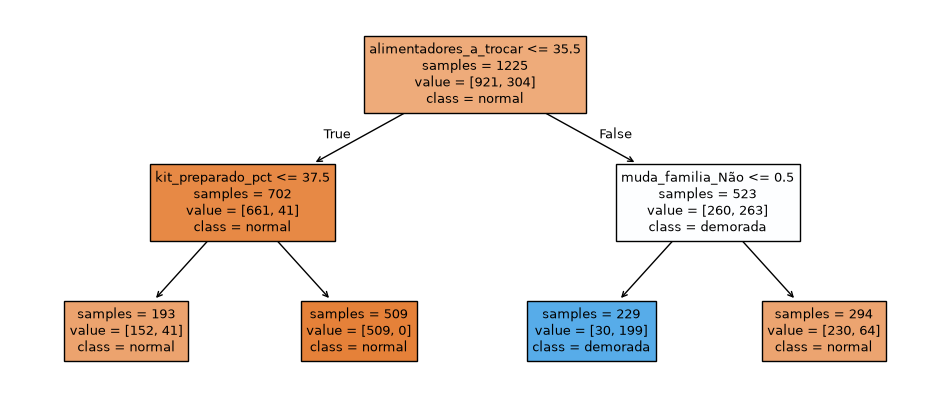

In [6]:
# Célula pronta: execute sem alterar (confere a Sua vez 1 e desenha a árvore)
if not hasattr(arvore_clf, 'tree_'):
    raise ValueError('Confira a Sua vez 1: falta chamar arvore_clf.fit(X_treino, yc_treino).')
if arvore_clf.max_depth != 2:
    raise ValueError('Confira a Sua vez 1: a atividade pede max_depth=2.')
ref_clf = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_treino, yc_treino)
if (arvore_clf.predict(X_val) != ref_clf.predict(X_val)).any():
    raise ValueError('Confira a Sua vez 1: DecisionTreeClassifier(max_depth=2, random_state=42); fit com (X_treino, yc_treino).')
print('Certo.')
fig, ax = plt.subplots(figsize=(12, 5))
plot_tree(arvore_clf, feature_names=ENTRADAS, class_names=NOMES, filled=True, impurity=False, proportion=False, fontsize=9, ax=ax)
plt.show()

### Sua vez 2 · Prever e contar os acertos e os erros
Faça as previsões da árvore para `X_val`. Depois use `confusion_matrix(real, previsto)`: ela devolve a matriz de confusão e o `.ravel()` a transforma em quatro números, na ordem **VN, FP, FN, VP**. Complete com o `real` (`yc_val`) e o `previsto`, nessa ordem.

- `X_val`: as características dos casos de validação.
- `yc_val`: a resposta real (sim/não) desses casos.

Na matriz, a linha de cima é o que era "não" (VN e FP) e a de baixo é o que era "sim" (FN e VP).

Troque cada `____` pela resposta antes de executar a célula.

In [7]:
# Sua vez: complete os espaços em branco
# O ravel() devolve os quatro números nesta ordem: VN, FP, FN, VP.
previsto_clf = arvore_clf.predict(X_val)
vn, fp, fn, vp = confusion_matrix(yc_val, previsto_clf).ravel()

Certo.


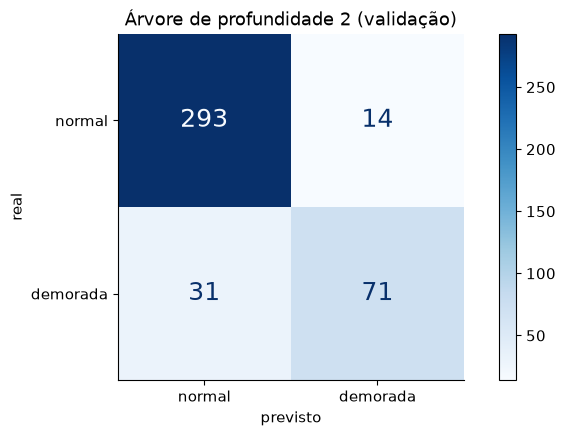

A árvore acertou 71 de 102 trocas demoradas (VP), deixou passar 31 (FN) e deu 14 alertas à toa (FP).
Acurácia (% de acertos): 89,0%.


In [8]:
# Célula pronta: execute sem alterar (confere a Sua vez 2 e mostra a matriz)
if len(previsto_clf) != len(yc_val):
    raise ValueError('Confira a Sua vez 2: o predict é com X_val.')
r = contar(yc_val, previsto_clf)
if (vp, fn, fp, vn) != (r['VP'], r['FN'], r['FP'], r['VN']):
    raise ValueError('Confira a Sua vez 2: confusion_matrix(real, previsto), nessa ordem, com yc_val e previsto_clf.')
print('Certo.')
ConfusionMatrixDisplay.from_predictions(yc_val, previsto_clf, labels=[0, 1], display_labels=NOMES, cmap='Blues', text_kw={'fontsize': 18})
plt.title('Árvore de profundidade 2 (validação)'); plt.xlabel('previsto'); plt.ylabel('real'); plt.show()
print(f"A árvore acertou {vp} de {int(yc_val.sum())} trocas demoradas (VP), deixou passar {fn} (FN) e deu {fp} alertas à toa (FP).")
print(f"Acurácia (% de acertos): {fmt(r['% de acertos'], 1)}%.")

### Acurácia, recall, precisão e F1
Com os mesmos números (VP, FN, FP e VN):
- **Acurácia:** % de acertos no total, (VP + VN) ÷ todos. Engana quando o "sim" é raro.
- **Recall:** dos casos "sim", quantos o modelo encontrou? Recall = VP ÷ (VP + FN). Cada **FN** (perdido) baixa o recall.
- **Precisão:** dos alertas, quantos estavam certos? Precisão = VP ÷ (VP + FP). Cada **FP** (falso alarme) baixa a precisão.
- **F1:** junta recall e precisão; F1 = 2 × VP ÷ (2 × VP + FP + FN). Só é alto se os dois forem altos.

In [9]:
# Célula pronta: execute sem alterar (mostra recall, precisão e F1)
r_arvore = contar(yc_val, previsto_clf)
display(pd.DataFrame({'Árvore (profundidade 2)': {'acurácia %': r_arvore['% de acertos'], **medidas(r_arvore)}}))
print('A acurácia mostra o total de acertos; o recall mostra os FN (casos "sim" que passaram) e a precisão mostra os FP (alertas à toa).')

,Árvore (profundidade 2)
acurácia %,89.0
recall %,69.6
precisão %,83.5
F1 %,75.9


A acurácia mostra o total de acertos; o recall mostra os FN (casos "sim" que passaram) e a precisão mostra os FP (alertas à toa).


## 2.5 · Escolher a profundidade pela validação

> **Contexto:** É a mesma regra da regressão: o **treino** aprende e a **validação** escolhe. A árvore sem limite quase não erra no treino e, mesmo assim, pode errar mais na validação.

A tabela mostra, para cada profundidade, o resultado no **treino** (só o total de erros) e na **validação**, sempre pelo total de erros (**erros** = FN + FP, os dois jeitos de errar). Quem decide a profundidade é a coluna **Validação: erros**.

> **Por que só os erros?** Daria para comparar as profundidades por outras medidas, como a acurácia, o recall, a precisão ou o F1. Aqui usamos o total de erros porque é o critério principal e o mais fácil de conferir. Na validação, a profundidade com menos erros é também a de maior acurácia.

**Você escolhe quais profundidades comparar.** Na primeira linha da célula abaixo está a lista `PROFUNDIDADES`, que já vem com `[1, 2, 4, 6, None]`. Pode manter ou trocar (por exemplo, `[1, 3, 5, 8, None]`); `None` é "sem limite". Use de 2 a 6 valores. Com outra lista, os números mudam em relação aos da turma, e tudo bem: a escolha vale para a lista que você comparou.

,Profundidade,Treino: erros,Validação: erros
0,1,301,93
1,2,135,45
2,4,75,33
3,6,54,34
4,sem limite,0,38


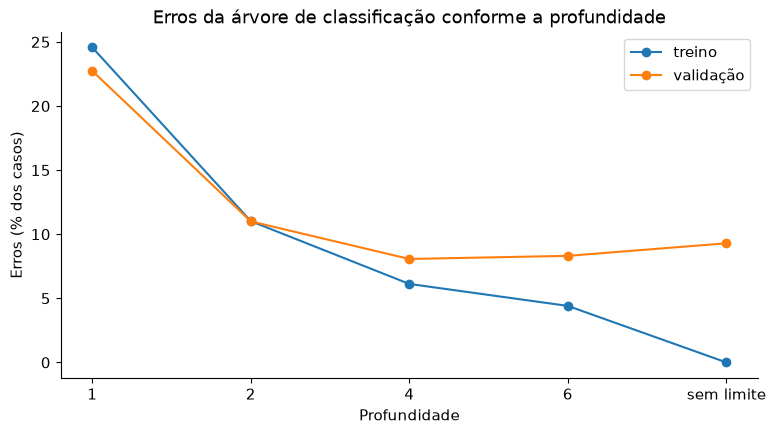

In [10]:
# Célula pronta: execute sem alterar (compara as profundidades). Só a lista da primeira linha pode ser trocada.
PROFUNDIDADES = [1, 2, 4, 6, None]   # troque pela lista que você quer comparar (None = sem limite)
valida = isinstance(PROFUNDIDADES, (list, tuple)) and all(p is None or (type(p) is int and p >= 1) for p in PROFUNDIDADES)
if not valida or not 2 <= len(set(PROFUNDIDADES)) <= 6:
    raise ValueError('PROFUNDIDADES: use de 2 a 6 valores diferentes, inteiros a partir de 1, e None para "sem limite".')
PROFUNDIDADES = sorted(set(PROFUNDIDADES), key=lambda p: float('inf') if p is None else p)

linhas = []
for prof in PROFUNDIDADES:
    arv = DecisionTreeClassifier(max_depth=prof, random_state=42).fit(X_treino, yc_treino)
    rt, rv = contar(yc_treino, arv.predict(X_treino)), contar(yc_val, arv.predict(X_val))
    linhas.append({'Profundidade': 'sem limite' if prof is None else prof,
                   'Treino: erros': rt['FN'] + rt['FP'],
                   'Validação: erros': rv['FN'] + rv['FP']})
tabela_clf = pd.DataFrame(linhas)
display(tabela_clf)
fig, ax = plt.subplots()
pos = range(len(tabela_clf))
ax.plot(pos, tabela_clf['Treino: erros'] / len(yc_treino) * 100, marker='o', label='treino')
ax.plot(pos, tabela_clf['Validação: erros'] / len(yc_val) * 100, marker='o', label='validação')
ax.set_xticks(list(pos), tabela_clf['Profundidade'].astype(str))
ax.set(xlabel='Profundidade', ylabel='Erros (% dos casos)', title='Erros da árvore de classificação conforme a profundidade')
ax.legend()
plt.show()

### Sua vez 3 · Profundidade escolhida
Escreva, entre as profundidades da sua lista, a que tem **menos erros na validação** (coluna **Validação: erros**). Se houver empate, fique com a **menor** (a árvore mais simples). `None` se for "sem limite".

Troque cada `____` pela resposta antes de executar a célula.

In [11]:
# Sua vez: complete os espaços em branco
profundidade_clf = 4   # None se for sem limite

Certo.


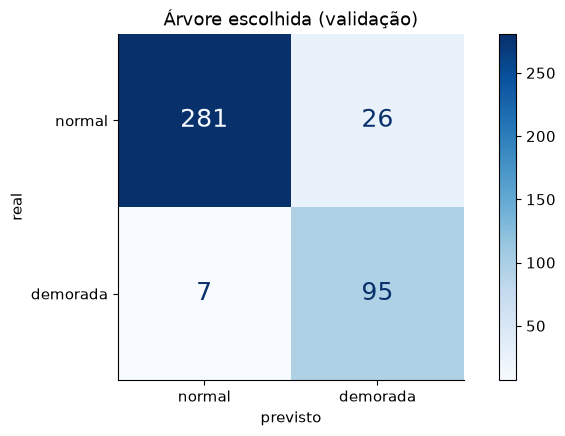

Árvore escolhida (profundidade 4): VP 95 de 102, FN 7, FP 26.


,Árvore escolhida (validação)
acurácia %,91.9
recall %,93.1
precisão %,78.5
F1 %,85.2


In [12]:
# Célula pronta: execute sem alterar (confere a Sua vez 3 e mostra a árvore escolhida)
if profundidade_clf not in PROFUNDIDADES:
    raise ValueError('Confira a Sua vez 3: a profundidade escolhida precisa estar na lista PROFUNDIDADES que você comparou.')
ev = tabela_clf['Validação: erros']
melhor_clf = PROFUNDIDADES[int(ev[ev == ev.min()].index[0])]
if profundidade_clf != melhor_clf:
    raise ValueError('Confira a Sua vez 3: menor número na coluna "Validação: erros"; no empate, a menor profundidade.')
arvore_clf_final = DecisionTreeClassifier(max_depth=profundidade_clf, random_state=42).fit(X_treino, yc_treino)
previsto_final = arvore_clf_final.predict(X_val)
r_final = contar(yc_val, previsto_final)
print('Certo.')
ConfusionMatrixDisplay.from_predictions(yc_val, previsto_final, labels=[0, 1], display_labels=NOMES, cmap='Blues', text_kw={'fontsize': 18})
plt.title('Árvore escolhida (validação)'); plt.xlabel('previsto'); plt.ylabel('real'); plt.show()
print(f"Árvore escolhida (profundidade {'sem limite' if profundidade_clf is None else profundidade_clf}): "
      f"VP {r_final['VP']} de {int(yc_val.sum())}, FN {r_final['FN']}, FP {r_final['FP']}.")
display(pd.DataFrame({'Árvore escolhida (validação)': {'acurácia %': r_final['% de acertos'], **medidas(r_final)}}))


## 2.6 · Interpretar os resultados

Use a matriz e as medidas da **árvore escolhida** (a tabela que aparece logo depois da Sua vez 3) e responda em poucas frases. **Para escrever:** dê dois cliques nesta célula, escreva depois de “Resposta:” e aperte Shift+Enter.

1. **Acurácia:** qual é a acurácia da árvore escolhida? Só com esse número dá para saber de que jeito ela errou? Por quê?
2. **Os dois erros:** a árvore errou mais por **falso negativo** (deixou passar um "sim") ou por **falso positivo** (alerta à toa)? Cite os dois números da matriz.
3. **Treino × validação:** olhe a tabela de profundidades. A árvore mais funda da sua lista erra menos no treino? E na validação? O que isso mostra?
4. **Recall e precisão:** explique com as suas palavras o que o recall e a precisão da árvore escolhida querem dizer, usando os números da matriz. Qual dos dois o erro que você citou na pergunta 2 derruba?

**Resposta:** 

1. **Acurácia:** a árvore de profundidade 4 acerta **91,9%** dos casos da validação (VN 281 + VP 95 de 409). Esse número sozinho não mostra de que jeito ela errou: os 33 erros podem ser trocas demoradas que passaram ou alarmes à toa, e a acurácia soma os dois.
2. **Os dois erros:** errou mais por **falso positivo**: **26 FP** (troca normal apontada como demorada) contra **7 FN** (troca demorada que passou). Ela encontrou 95 das 102 trocas demoradas da validação.
3. **Treino × validação:** a árvore sem limite erra **0** casos no treino, o menor valor da tabela, mas erra **38** na validação, mais que a de profundidade 4 (33). Isso mostra que ela decorou o treino e generaliza pior, por isso a escolha é feita pela validação.
4. **Recall e precisão:** o **recall de 93,1%** quer dizer que, de cada 100 trocas demoradas, a árvore apontou cerca de 93 (VP 95 ÷ 102). A **precisão de 78,5%** quer dizer que, de cada 100 alertas, cerca de 78 eram mesmo demorados (VP 95 ÷ 121). O erro citado na pergunta 2, o falso positivo, derruba a **precisão**; os poucos FN mantêm o recall alto. Na prática, a ajuda extra seria dada a algumas trocas que não precisavam, mas quase nenhuma troca demorada ficaria sem apoio.

## 2.7 · Salvar a classificação

Primeiro salve as escolhas feitas **só com a validação**: o teste ainda está fechado. Ele é aberto na seção 2.8, logo abaixo. Baixe `N4_classificacao.json` pelo painel **Arquivos**.

A **resposta escrita** fica no notebook (por isso salve uma cópia no Drive); o `.json` guarda só os números.

In [13]:
# Célula pronta: execute sem alterar (salva as escolhas no .json)
SAIDA = Path('outputs/metrics')
SAIDA.mkdir(parents=True, exist_ok=True)
_arq = SAIDA / 'N4_classificacao.json'
if _arq.exists() and json.loads(_arq.read_text(encoding='utf-8')).get('teste_aberto'):
    registro_clf = json.loads(_arq.read_text(encoding='utf-8'))
    print('O teste já foi aberto: a escolha fica como está e não é salva de novo. Siga para a interpretação (2.6) e para a apresentação.')
else:
    registro_clf = {
        'classe': CLASSE, 'regra': 'tempo_troca_min > 42', 'nomes': NOMES,
        'casos_sim_validacao': int(yc_val.sum()), 'casos_validacao': int(len(yc_val)),
        'tabela_profundidades': tabela_clf.astype({'Profundidade': str}).to_dict('records'),
        'profundidade_escolhida': profundidade_clf,
        'arvore_validacao': r_final,
        'medidas_validacao': {'arvore': medidas(r_final)},
        'teste_aberto': False,
    }
    (SAIDA / 'N4_classificacao.json').write_text(json.dumps(registro_clf, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    print('Salvo em', (SAIDA / 'N4_classificacao.json').resolve())

Salvo em outputs/metrics/N4_classificacao.json


## 2.8 · Abrir o teste (uma única vez)

> **Contexto:** Como na regressão, o teste só é aberto depois de **todas as escolhas** (profundidade e `.json` salvos). Ele mostra como a árvore escolhida se sai em casos que ela nunca viu e que não ajudaram em nenhuma escolha.

A célula está pronta: só execute. **Depois de ver o teste, não volte para mudar a profundidade**: se mudar, o teste deixa de ser um teste.

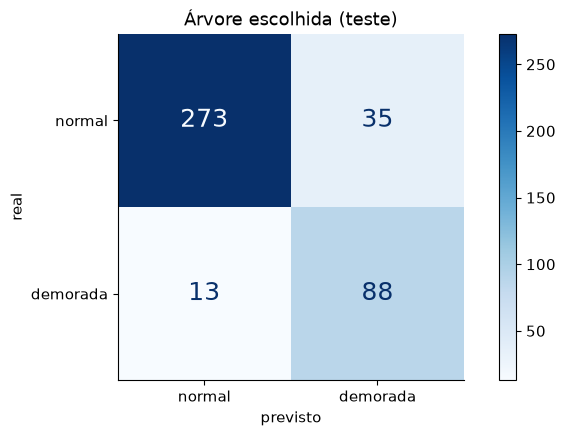

,Árvore · validação,Árvore · teste
acurácia %,91.9,88.3
recall %,93.1,87.1
precisão %,78.5,71.5
F1 %,85.2,78.6


No teste: VP 88 de 101, FN 13, FP 35.
Atualizado com o teste: outputs/metrics/N4_classificacao.json


In [14]:
# Célula pronta: execute uma única vez, depois de salvar o .json da seção 2.7.
if 'SAIDA' not in globals() or 'registro_clf' not in globals():
    raise RuntimeError('Antes de abrir o teste, execute a seção 2.7 (salvar a escolha). O teste só abre depois.')
_arq = SAIDA / 'N4_classificacao.json'
if not _arq.exists():
    raise RuntimeError('Antes de abrir o teste, execute a seção 2.7 (salvar a escolha). O teste só abre depois.')
if json.loads(_arq.read_text(encoding='utf-8')).get('teste_aberto'):
    print('O teste já foi aberto e não é aberto de novo. Resultado salvo:')
    print(json.loads(_arq.read_text(encoding='utf-8'))['arvore_teste'])
else:
    previsto_teste = arvore_clf_final.predict(X_teste)
    r_teste = contar(yc_teste, previsto_teste)
    ConfusionMatrixDisplay.from_predictions(yc_teste, previsto_teste, labels=[0, 1], display_labels=NOMES, cmap='Blues', text_kw={'fontsize': 18})
    plt.title('Árvore escolhida (teste)'); plt.xlabel('previsto'); plt.ylabel('real'); plt.show()
    display(pd.DataFrame({
        'Árvore · validação': {'acurácia %': r_final['% de acertos'], **medidas(r_final)},
        'Árvore · teste': {'acurácia %': r_teste['% de acertos'], **medidas(r_teste)},
    }))
    print(f"No teste: VP {r_teste['VP']} de {int(yc_teste.sum())}, FN {r_teste['FN']}, FP {r_teste['FP']}.")
    registro_clf.update({'teste_aberto': True, 'arvore_teste': r_teste, 'medidas_teste': medidas(r_teste)})
    _arq.write_text(json.dumps(registro_clf, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    print('Atualizado com o teste:', _arq.resolve())

**Para a apresentação de 09/11:** levem a matriz e as medidas do **teste** (VP, FN, FP, recall, precisão e F1) e comparem com a validação. Se o teste ficar pior que a validação, digam isso: é um resultado honesto, não um erro. Baixe de novo `N4_classificacao.json` pelo painel **Arquivos** (agora com o teste) e salve uma cópia do notebook no Drive.